In [1]:

# REDES NEURONALES III
# Notebook 2: Optimización e hiperparámetros

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# Fijar semillas
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Entorno preparado correctamente.")


TensorFlow: 2.21.0
Entorno preparado correctamente.


In [2]:

# Cargar MNIST
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# Separar Train y Dev
x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

# Normalizar las imágenes
x_train = x_train.astype("float32") / 255.0
x_dev = x_dev.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Verificar dimensiones
print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [3]:

# Función para crear el modelo de experimentación
def crear_modelo_experimento(optimizador, units=128):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo

print("Función del modelo creada correctamente.")


Función del modelo creada correctamente.


In [4]:

# Configuración de los optimizadores
optimizadores = {
    "SGD Momentum": keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),
    "RMSprop": keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    "Adam": keras.optimizers.Adam(
        learning_rate=0.001
    )
}

print("Optimizadores configurados:")
for nombre in optimizadores:
    print("-", nombre)


Optimizadores configurados:
- SGD Momentum
- RMSprop
- Adam


In [5]:

# Entrenar un modelo con cada optimizador
resultados = []
historias = {}

for nombre, optimizador in optimizadores.items():
    print(f"\nEntrenando modelo con: {nombre}")

    # Crear un modelo nuevo para cada optimizador
    modelo = crear_modelo_experimento(
        optimizador=optimizador
    )

    # Entrenar durante 5 épocas
    historia = modelo.fit(
        x_train,
        y_train,
        validation_data=(x_dev, y_dev),
        epochs=5,
        batch_size=64,
        verbose=1
    )

    # Guardar la historia para las gráficas
    historias[nombre] = historia

    # Registrar los resultados de la última época
    resultados.append({
        "Optimizador": nombre,
        "Train Accuracy": historia.history["accuracy"][-1],
        "Dev Accuracy": historia.history["val_accuracy"][-1],
        "Train Loss": historia.history["loss"][-1],
        "Dev Loss": historia.history["val_loss"][-1]
    })

# Crear tabla comparativa
tabla_resultados = pd.DataFrame(resultados)

print("\nRESULTADOS COMPARATIVOS")
display(tabla_resultados.round(4))



Entrenando modelo con: SGD Momentum
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8808 - loss: 0.4241 - val_accuracy: 0.9220 - val_loss: 0.2693
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9354 - loss: 0.2258 - val_accuracy: 0.9388 - val_loss: 0.2114
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9506 - loss: 0.1733 - val_accuracy: 0.9482 - val_loss: 0.1823
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9603 - loss: 0.1405 - val_accuracy: 0.9538 - val_loss: 0.1615
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9663 - loss: 0.1177 - val_accuracy: 0.9575 - val_loss: 0.1462

Entrenando modelo con: RMSprop
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9111 - loss: 0.3184 - val_accuracy: 0.9463 - val_loss: 0.1876
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9567 - loss: 0.1486 - val_accuracy: 0.9585 - val_loss: 0.1422
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 

,Optimizador,Train Accuracy,Dev Accuracy,Train Loss,Dev Loss
0,SGD Momentum,0.9663,0.9575,0.1177,0.1462
1,RMSprop,0.9814,0.9679,0.0652,0.1109
2,Adam,0.9829,0.9658,0.0610,0.1146


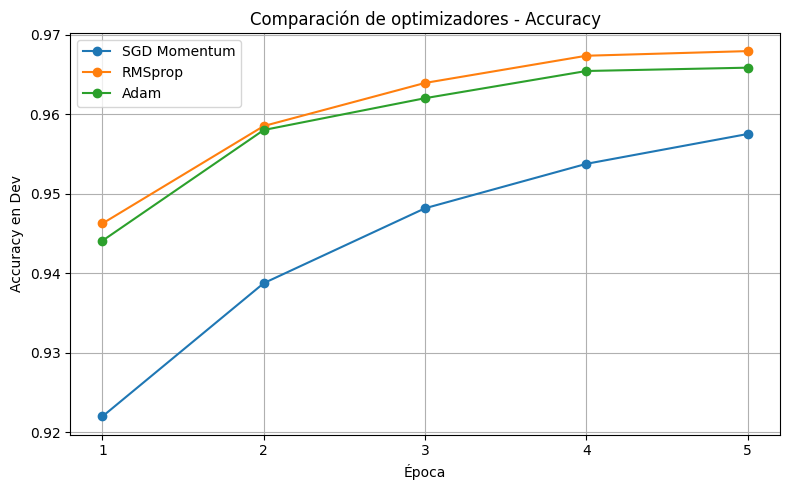

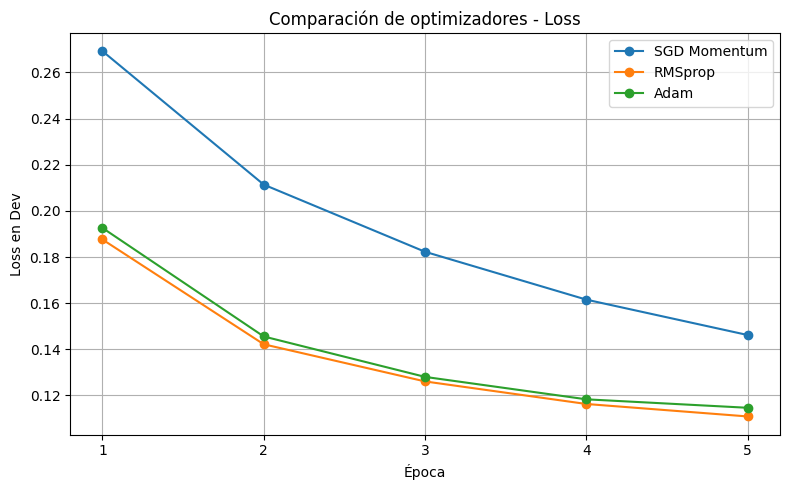

In [6]:

# Comparación de Accuracy en Dev
plt.figure(figsize=(8, 5))

for nombre, historia in historias.items():
    plt.plot(
        range(1, len(historia.history["val_accuracy"]) + 1),
        historia.history["val_accuracy"],
        marker="o",
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Accuracy en Dev")
plt.title("Comparación de optimizadores - Accuracy")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Comparación de Loss en Dev
plt.figure(figsize=(8, 5))

for nombre, historia in historias.items():
    plt.plot(
        range(1, len(historia.history["val_loss"]) + 1),
        historia.history["val_loss"],
        marker="o",
        label=nombre
    )

plt.xlabel("Época")
plt.ylabel("Loss en Dev")
plt.title("Comparación de optimizadores - Loss")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [7]:

# EXPERIMENTO: COMPARACIÓN DE LEARNING RATE CON ADAM

learning_rates = [0.0001, 0.001, 0.01]

resultados_lr = []
historias_lr = {}

for lr in learning_rates:
    print(f"\nEntrenando con learning rate = {lr}")

    # Reiniciar el estado del modelo para cada experimento
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    # Mantener la misma arquitectura del baseline
    modelo = crear_modelo_experimento(
        keras.optimizers.Adam(learning_rate=lr)
    )

    # Entrenar durante 3 épocas
    historia = modelo.fit(
        x_train,
        y_train,
        validation_data=(x_dev, y_dev),
        epochs=3,
        batch_size=64,
        verbose=1
    )

    historias_lr[lr] = historia

    # Guardar las métricas finales
    resultados_lr.append({
        "Learning Rate": lr,
        "Train Accuracy": historia.history["accuracy"][-1],
        "Dev Accuracy": historia.history["val_accuracy"][-1],
        "Train Loss": historia.history["loss"][-1],
        "Dev Loss": historia.history["val_loss"][-1]
    })

# Mostrar tabla comparativa
tabla_lr = pd.DataFrame(resultados_lr)

print("\nRESULTADOS COMPARATIVOS DE LEARNING RATE")
display(tabla_lr.round(4))



Entrenando con learning rate = 0.0001
Epoch 1/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7784 - loss: 0.8832 - val_accuracy: 0.8903 - val_loss: 0.4393
Epoch 2/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9004 - loss: 0.3721 - val_accuracy: 0.9116 - val_loss: 0.3305
Epoch 3/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9176 - loss: 0.3026 - val_accuracy: 0.9226 - val_loss: 0.2869

Entrenando con learning rate = 0.001
Epoch 1/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9094 - loss: 0.3244 - val_accuracy: 0.9467 - val_loss: 0.1924
Epoch 2/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9564 - loss: 0.1511 - val_accuracy: 0.9581 - val_loss: 0.1458
Epoch 3/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9690 - loss: 0.1068 - val_accuracy: 0.9627 - val_loss: 0.1281

Entrenando con learning rate = 0.01
Epoch 1/3
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9292 - loss: 0.2319 - val_accuracy: 0.9556 - val_loss: 0.

,Learning Rate,Train Accuracy,Dev Accuracy,Train Loss,Dev Loss
0,0.0001,0.9176,0.9226,0.3026,0.2869
1,0.0010,0.9690,0.9627,0.1068,0.1281
2,0.0100,0.9671,0.9583,0.1092,0.1702


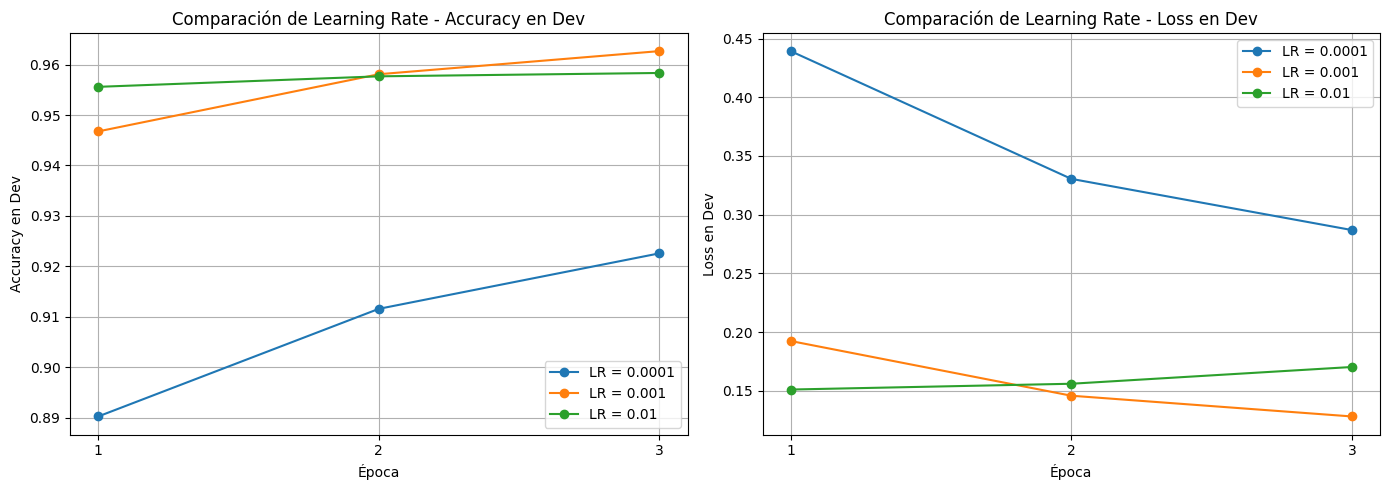

In [8]:

# COMPARACIÓN GRÁFICA DE LEARNING RATE

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr, historia in historias_lr.items():
    epocas = range(1, len(historia.history["val_accuracy"]) + 1)

    axes[0].plot(
        epocas,
        historia.history["val_accuracy"],
        marker="o",
        label=f"LR = {lr}"
    )

    axes[1].plot(
        epocas,
        historia.history["val_loss"],
        marker="o",
        label=f"LR = {lr}"
    )

axes[0].set_title("Comparación de Learning Rate - Accuracy en Dev")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy en Dev")
axes[0].set_xticks([1, 2, 3])
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Comparación de Learning Rate - Loss en Dev")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss en Dev")
axes[1].set_xticks([1, 2, 3])
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()
